# EWELD C24 — Confronto side-by-side dei modelli
Notebook autonomo basato su `EWELD_C24_forecasting.ipynb`; gli altri notebook non vengono eseguiti né modificati.

Confrontiamo **Persistenza, Naive stagionale 24h e 168h, Media mobile 24h, ARIMA, SARIMA e SARIMAX + calendario**, usando lo stesso train, lo stesso test e previsioni multi-step senza aggiornamenti con valori reali del test. Seguono il caso giornaliero U143 e una walk-forward opzionale.

**Parametri selezionati automaticamente:** ARIMA, SARIMA e SARIMAX vengono ottimizzati separatamente sul train. Tabelle ed etichette ARIMA riportano i parametri effettivamente scelti.

Eseguire le celle dall’alto verso il basso. Dipendenze: numpy, pandas, matplotlib, statsmodels, IPython. I fit statistici possono richiedere alcuni minuti.

Prima dei confronti, una grid search seleziona separatamente gli ordini ARIMA, SARIMA e SARIMAX usando solo il train. Il test finale non viene usato per scegliere i parametri.

In [1]:
from pathlib import Path
from time import perf_counter
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Funziona avviando il kernel dalla radice del progetto o da datasets.
DATA_ROOT = next((p for p in (Path.cwd() / 'datasets', Path.cwd())
                  if (p / 'EWELD/Electricity Consumption/C/C24 Manufacture of basic metals').exists()), None)
if DATA_ROOT is None:
    raise FileNotFoundError('Avviare il notebook dalla radice del progetto o da datasets.')
C24_DIR = DATA_ROOT / 'EWELD/Electricity Consumption/C/C24 Manufacture of basic metals'
USER = 'U141'
N_GIORNI_TRAIN = 60
H = 48
W = 24
MAXITER = 100  # usato sia nella ricerca sia nei fit finali
RUN_WALK_FORWARD = False  # True per riaddestrare tutti e sette i modelli su più fold
N_FOLDS, WF_TRAIN_DAYS, STEP = 12, 30, 48
CAPODANNO_LUNARE = {2016:'2016-02-08', 2017:'2017-01-28', 2018:'2018-02-16',
                    2019:'2019-02-05', 2020:'2020-01-25', 2021:'2021-02-12', 2022:'2022-02-01'}
PERIODI_COVID = [('2020-01-23', '2020-04-08')]
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2, 'font.size': 10})

# Tutte le combinazioni del prodotto cartesiano, senza campionamento.
# Ampliare per esempio p/q a [0, 1, 2]; il costo cresce rapidamente.
PARAM_GRID = {'p': [0, 1], 'd': [0, 1], 'q': [0, 1],
              'P': [0, 1], 'D': [0, 1], 'Q': [0, 1]}
TUNING_FOLDS = 2
TUNING_METRIC = 'RMSE'  # alternative: 'MAE', 'sMAPE %', 'MASE'


## 1. Dati e finestra comune
Riprendiamo il taglio iniziale e la selezione della finestra operativa del sorgente. La somma oraria richiede quattro misure valide: i buchi restano mancanti e interrompono il segmento disponibile, senza essere trasformati in consumo zero.

**Limite del confronto:** la selezione dei tratti operativi osserva retrospettivamente anche il periodo di test. Questo benchmark misura quindi la prestazione **condizionata all’operatività**, non la capacità di prevedere fermi imprevisti o la prestazione in produzione.

In [2]:
# --- Taglio del tratto iniziale non rappresentativo (stesso criterio dell'EDA) ---
def taglia_da_operativo(s, min_fermo_giorni=30, entro_frazione=0.5, soglia=0.05, verbose=True):
    """Rimuove SOLO il lungo fermo INIZIALE (>= min_fermo_giorni) se termina entro 'entro_frazione'
    della durata. Adattiva: se non c'e' un lungo fermo iniziale restituisce la serie invariata."""
    d = s.resample("D").sum(); med = d[d > 0].median()
    if not med or med != med: return s
    idle = (d < soglia * med); grp = (idle != idle.shift()).cumsum()
    tot = (d.index.max() - d.index.min()).days
    limite = d.index.min() + pd.Timedelta(days=int(tot * entro_frazione))
    fine_taglio = None
    for _, g in d.groupby(grp):
        if idle.loc[g.index].iloc[0] and len(g) >= min_fermo_giorni and g.index.max() <= limite:
            fine_taglio = g.index.max()
    if fine_taglio is None:
        if verbose: print("taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.")
        return s
    start = fine_taglio + pd.Timedelta(days=1)
    if verbose: print(f"taglia_da_operativo: serie dal {start.date()} (rimossi ~{(start - s.index.min()).days} giorni).")
    return s.loc[start:]

def load_user(u):
    d = pd.read_csv(C24_DIR / f'{u}.csv')
    d['t'] = pd.to_datetime(d['Time'])
    d = d.set_index('t').sort_index()
    return d['Value'].clip(lower=0)

In [3]:
def elenco_fermi(y, soglia=0.05, min_giorni=10):
    """Diagnostica: elenca i fermi (>= min_giorni) presenti nella serie oraria."""
    d = y.resample("D").sum(); med = d[d>0].median()
    idle = d < soglia*med; grp = (idle!=idle.shift()).cumsum()
    out = [(g.index.min().date(), g.index.max().date(), len(g))
           for _,g in d.groupby(grp) if idle.loc[g.index].iloc[0] and len(g)>=min_giorni]
    return out

def finestra_operativa(y, n_giorni_train, H, soglia=0.05, verbose=True):
    """Restituisce il tratto operativo CONTINUO piu recente lungo (n_giorni_train*24 + H) ore,
    senza fermi interni. Se non esiste un tratto abbastanza lungo, usa il piu lungo disponibile."""
    need = n_giorni_train*24 + H
    med = y[y>0].median()
    ok = y >= soglia*med
    grp = (ok != ok.shift()).cumsum()
    segmenti_ok = [g for _,g in y.groupby(grp) if ok.loc[g.index].iloc[0]]
    validi = [g for g in segmenti_ok if len(g) >= need]
    if validi:
        win = validi[-1].iloc[-need:]                     # il piu recente, sue ultime `need` ore
    else:
        piu_lungo = max(segmenti_ok, key=len)
        win = piu_lungo
        if verbose: print(f"ATTENZIONE: nessun tratto operativo continuo di {need} h; uso il piu lungo ({len(win)} h).")
    if verbose:
        print(f"Finestra operativa: {win.index.min()} -> {win.index.max()} ({len(win)} h) | fermi interni: 0")
    return win

In [4]:
raw = load_user(USER)
if raw.index.has_duplicates:
    raise ValueError('Timestamp duplicati: verificare il CSV prima del confronto.')
raw = raw.replace([np.inf, -np.inf], np.nan)
s = taglia_da_operativo(raw)
y = s.resample('h').sum(min_count=4).asfreq('h')
if not (y > 0).any():
    raise ValueError('Nessun dato operativo positivo disponibile.')
win = finestra_operativa(y, N_GIORNI_TRAIN, H)
train, test = win.iloc[:-H], win.iloc[-H:]
assert len(train) > max(168, W) and len(test) == H, 'Storico insufficiente.'
assert np.isfinite(win).all() and win.index.equals(pd.date_range(win.index[0], periods=len(win), freq='h'))
display(pd.DataFrame({'campione': ['train', 'test'], 'inizio': [train.index[0], test.index[0]],
                      'fine': [train.index[-1], test.index[-1]], 'ore': [len(train), len(test)]}))
print(f'{USER}: {y.isna().sum()} ore mancanti/incomplete escluse dai segmenti operativi.')

taglia_da_operativo: nessun lungo fermo iniziale, serie invariata.
Finestra operativa: 2021-10-31 00:00:00 -> 2021-12-31 23:00:00 (1488 h) | fermi interni: 0


,campione,inizio,fine,ore
0,train,2021-10-31,2021-12-29 23:00:00,1440
1,test,2021-12-30,2021-12-31 23:00:00,48


U141: 0 ore mancanti/incomplete escluse dai segmenti operativi.


## 2. Motore di confronto e metriche
MAE e RMSE sono espressi nell’unità della serie; sMAPE è percentuale. Il MASE usa la scala del naive stagionale **sul solo train** (24 ore o 7 giorni). MASE < 1 indica un errore inferiore a quella scala storica, non necessariamente al naive multi-step sul test. Una scala nulla rende MASE non definito.

Selezioniamo gli ordini ARIMA/SARIMA/SARIMAX sul train; conserviamo assenza di vincoli di stazionarietà/invertibilità e previsioni non troncate del confronto orario originale. Le colonne esogene costanti vengono eliminate usando esclusivamente il train. Warning, convergenza e tempi restano visibili.

In [5]:
def _finestre_cny(gp=7, gd=10):
    return [(pd.Timestamp(d)-pd.Timedelta(days=gp), pd.Timestamp(d)+pd.Timedelta(days=gd))
            for d in CAPODANNO_LUNARE.values()]

def make_exog(idx, K=3):
    df = pd.DataFrame(index=idx)
    how = idx.dayofweek*24 + idx.hour          # ora nella settimana: 0..167
    for k in range(1, K+1):
        df[f"wk_sin{k}"] = np.sin(2*np.pi*k*how/168)
        df[f"wk_cos{k}"] = np.cos(2*np.pi*k*how/168)
    festa = np.zeros(len(idx))
    for a, b in _finestre_cny():
        festa += ((idx >= a) & (idx <= b)).astype(float)
    df["festa_lunare"] = np.clip(festa, 0, 1)
    covid = np.zeros(len(idx))
    for a, b in PERIODI_COVID:
        covid += ((idx >= pd.Timestamp(a)) & (idx <= pd.Timestamp(b))).astype(float)
    df["covid"] = np.clip(covid, 0, 1)
    return df           # scarta le colonne costanti (es. eventi assenti)

In [6]:
def metriche(tr, te, pred, m=24):
    actual, predicted = np.asarray(te, float), np.asarray(pred, float)
    if actual.shape != predicted.shape or not np.isfinite(predicted).all():
        raise ValueError('Previsione non finita o con dimensione errata.')
    error = actual - predicted
    denominator = np.abs(actual) + np.abs(predicted)
    smape = np.divide(2 * np.abs(error), denominator, out=np.zeros_like(error), where=denominator != 0)
    scale = tr.diff(m).abs().dropna().mean()
    mae = np.abs(error).mean()
    return {'MAE': mae, 'RMSE': np.sqrt(np.mean(error**2)), 'sMAPE %': smape.mean()*100,
            'MASE': mae/scale if np.isfinite(scale) and scale > 0 else np.nan}

### 2.1 Ricerca esaustiva prima del confronto
Proviamo **tutte le combinazioni nella griglia configurata** di `(p,d,q)(P,D,Q,m)`, separatamente per SARIMA e SARIMAX; ARIMA prova tutte le combinazioni di `(p,d,q)` della stessa griglia senza componente stagionale. Non esiste una ricerca finita su tutti gli interi: ampliare `PARAM_GRID` per estendere gli intervalli. Il periodo resta quello del dato: `m=24` per l’orario, `m=7` per il giornaliero.

La griglia iniziale contiene 8 combinazioni ARIMA e 64 per ciascuno dei due modelli stagionali: **272 fit** con due fold nel confronto orario. Nel caso giornaliero si confrontano solo SARIMA e SARIMAX (256 fit). Anche questa ricerca può richiedere molto tempo; ampliando sei intervalli il costo cresce moltiplicativamente.

Le ultime due finestre di `H` ore **del train** sono usate come validazione a origine crescente, con un nuovo fit per ciascuna origine. Vince il minor **RMSE medio di validazione** (metrica configurabile). Sono ammesse solo combinazioni con previsioni finite e convergenza in tutti i fold. Errori e warning restano nel log. Non scegliamo usando AIC o il test finale.

Dopo la ricerca i vincitori vengono riaddestrati su tutto il train e confrontati sul test riservato. “Migliore” significa migliore nella griglia e nella validazione scelte, non un ottimo universale.

In [7]:
from itertools import product

def ricerca_ordini(series, horizon, season, exog_builder, grid=None,
                   n_folds=None, metric=None, clip_zero=False, verbose=True, include_arima=True):
    """Grid search esaustiva su fold temporali interni alla sola serie di train.

    Restituisce parametri migliori, classifica e log di ogni fit/fold.
    La coppia order/seasonal_order viene scelta separatamente per ciascun modello richiesto.
    Nessun valore del test esterno entra in questa funzione.
    """
    grid = PARAM_GRID if grid is None else grid
    n_folds = TUNING_FOLDS if n_folds is None else n_folds
    metric = TUNING_METRIC if metric is None else metric
    if metric not in ('MAE', 'RMSE', 'sMAPE %', 'MASE'):
        raise ValueError('Metrica di selezione non riconosciuta.')
    keys = ('p', 'd', 'q', 'P', 'D', 'Q')
    if horizon < 1 or n_folds < 1 or season < 2:
        raise ValueError('Orizzonte/fold devono essere positivi; stagionalità >= 2.')
    for key in keys:
        if not grid.get(key) or any(not isinstance(v, (int, np.integer)) or v < 0 for v in grid[key]):
            raise ValueError(f'Griglia non valida per {key}: usare interi non negativi.')
    combos = list(product(*(sorted(set(grid[k])) for k in keys)))
    origins = [len(series) - horizon*i for i in range(n_folds, 0, -1)]
    if origins[0] <= max(2*season, W):
        raise ValueError('Train insufficiente per la validazione interna: ridurre fold/orizzonte.')
    folds = []
    for origin in origins:
        tr, va = series.iloc[:origin], series.iloc[origin:origin+horizon]
        ex_tr, ex_va = exog_builder(tr.index), exog_builder(va.index)
        cols = ex_tr.columns[ex_tr.std() > 1e-9]
        folds.append((tr, va, ex_tr[cols], ex_va[cols]))
    arima_combos = list(product(*(sorted(set(grid[k])) for k in keys[:3])))
    model_specs = [('SARIMA', False, combos), ('SARIMAX +cal', True, combos)]
    if include_arima:
        model_specs.insert(0, ('ARIMA', False, arima_combos))
    total = sum(len(candidates) for _, _, candidates in model_specs)*n_folds
    if verbose:
        print(f'Grid search: {dict((name, len(candidates)) for name, _, candidates in model_specs)} × {n_folds} fold = {total} fit.', flush=True)
        print(f'Selezione: {metric} medio minimo; richiesti tutti i fold convergenti.', flush=True)
    rows = []
    done = 0
    for model, use_exog, candidates in model_specs:
        for cid, values in enumerate(candidates):
            order = tuple(values[:3])
            seasonal = (0, 0, 0, 0) if model == 'ARIMA' else (*values[3:], season)
            for fold, (tr, va, ex_tr, ex_va) in enumerate(folds, 1):
                start = perf_counter()
                row = {'modello': model, 'candidato': cid, 'order': order, 'seasonal_order': seasonal,
                       'fold': fold, 'train_fine': tr.index[-1], 'val_inizio': va.index[0],
                       'val_fine': va.index[-1], 'errore': np.nan, 'convergenza': False, 'stato': 'OK'}
                caught = []
                try:
                    with warnings.catch_warnings(record=True) as caught:
                        warnings.simplefilter('always')
                        r = SARIMAX(tr, order=order, seasonal_order=seasonal,
                                    exog=ex_tr if use_exog and ex_tr.shape[1] else None,
                                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=MAXITER)
                        pred = r.get_forecast(len(va), exog=ex_va if use_exog and ex_va.shape[1] else None).predicted_mean
                        if clip_zero:
                            pred = pred.clip(lower=0)
                        score = metriche(tr, va, pred, m=season)[metric]
                        row['convergenza'] = bool(r.mle_retvals.get('converged', False))
                        row['errore'] = score
                        if not row['convergenza']:
                            row['stato'] = 'NON CONVERGENTE'
                        elif not np.isfinite(score):
                            row['stato'] = 'METRICA NON FINITA'
                except Exception as exc:
                    row['stato'] = f'ERRORE: {type(exc).__name__}: {exc}'
                row['warning'] = ' | '.join(dict.fromkeys(str(w.message) for w in caught))
                row['secondi'] = perf_counter() - start
                rows.append(row)
                done += 1
                if verbose and (done % 10 == 0 or done == total):
                    print(f'Fit completati: {done}/{total}', flush=True)
    dettagli = pd.DataFrame(rows)
    ranking = dettagli.groupby(['modello', 'candidato'], sort=False).agg(
        order=('order', 'first'), seasonal_order=('seasonal_order', 'first'),
        errore_medio=('errore', 'mean'), errore_std=('errore', 'std'),
        fold_validi=('stato', lambda s: s.eq('OK').sum()), secondi=('secondi', 'sum')).reset_index()
    ranking['ammissibile'] = (ranking['fold_validi'] == n_folds) & np.isfinite(ranking['errore_medio'])
    ranking = ranking.sort_values(['modello', 'ammissibile', 'errore_medio', 'candidato'], ascending=[True, False, True, True])
    best = {}
    for model, _, _ in model_specs:
        candidates = ranking[(ranking['modello'] == model) & ranking['ammissibile']]
        if not candidates.empty:
            winner = candidates.iloc[0]
            best[model] = (winner['order'], winner['seasonal_order'])
    return best, ranking, dettagli

def verifica_selezione(best, required=('ARIMA', 'SARIMA', 'SARIMAX +cal')):
    missing = set(required) - set(best)
    if missing:
        raise RuntimeError(f'Nessuna combinazione valida per {sorted(missing)}. '
                           'Consultare il log della ricerca, aumentare MAXITER o modificare la griglia; '
                           'il confronto non usa parametri di ripiego.')


In [8]:
best_params, classifica_ricerca, log_ricerca = ricerca_ordini(train, H, 24, make_exog)
display(classifica_ricerca.groupby('modello', sort=False).head(10))
display(log_ricerca.groupby(['modello', 'stato']).size().rename('numero_fit').to_frame())
verifica_selezione(best_params)
display(pd.DataFrame(best_params, index=['order', 'seasonal_order']))

Grid search: {'ARIMA': 8, 'SARIMA': 64, 'SARIMAX +cal': 64} × 2 fold = 272 fit.
Selezione: RMSE medio minimo; richiesti tutti i fold convergenti.
Fit completati: 10/272
Fit completati: 20/272
Fit completati: 30/272
Fit completati: 40/272
Fit completati: 50/272
Fit completati: 60/272
Fit completati: 70/272
Fit completati: 80/272
Fit completati: 90/272
Fit completati: 100/272
Fit completati: 110/272
Fit completati: 120/272
Fit completati: 130/272
Fit completati: 140/272
Fit completati: 150/272
Fit completati: 160/272
Fit completati: 170/272
Fit completati: 180/272
Fit completati: 190/272
Fit completati: 200/272
Fit completati: 210/272
Fit completati: 220/272
Fit completati: 230/272
Fit completati: 240/272
Fit completati: 250/272
Fit completati: 260/272
Fit completati: 270/272
Fit completati: 272/272


,modello,candidato,order,seasonal_order,errore_medio,errore_std,fold_validi,secondi,ammissibile
7,ARIMA,7,"(1, 1, 1)","(0, 0, 0, 0)",686.896867,194.281341,2,0.122409,True
3,ARIMA,3,"(0, 1, 1)","(0, 0, 0, 0)",745.669513,51.231156,2,0.029145,True
6,ARIMA,6,"(1, 1, 0)","(0, 0, 0, 0)",747.127110,47.922091,2,0.011859,True
2,ARIMA,2,"(0, 1, 0)","(0, 0, 0, 0)",762.501791,15.222931,2,0.011336,True
4,ARIMA,4,"(1, 0, 0)","(0, 0, 0, 0)",880.427632,289.003273,2,0.035199,True
5,ARIMA,5,"(1, 0, 1)","(0, 0, 0, 0)",884.301986,298.861120,2,0.038579,True
1,ARIMA,1,"(0, 0, 1)","(0, 0, 0, 0)",5870.053367,195.616613,2,0.039658,True
0,ARIMA,0,"(0, 0, 0)","(0, 0, 0, 0)",5919.797004,186.387457,2,0.012332,True
69,SARIMA,61,"(1, 1, 1)","(1, 0, 1, 24)",667.950534,127.287498,2,5.478438,True
53,SARIMA,45,"(1, 0, 1)","(1, 0, 1, 24)",672.984786,58.950482,2,2.778469,True


numero_fit
modello      stato                      
ARIMA        OK                       16
SARIMA       NON CONVERGENTE           1
             OK                      127
SARIMAX +cal OK                      128

,ARIMA,SARIMA,SARIMAX +cal
order,"(1, 1, 1)","(1, 1, 1)","(1, 1, 1)"
seasonal_order,"(0, 0, 0, 0)","(1, 0, 1, 24)","(1, 0, 1, 24)"


In [9]:
best_params['ARIMA'][0]  # ordine scelto dalla validazione

(1, 1, 1)

In [10]:
def confronta(tr, te, best_params):
    horizon = len(te)
    predictions, fits, rows = {}, {}, {}
    verifica_selezione(best_params)
    arima_name = 'ARIMA' + str(best_params['ARIMA'][0]).replace(' ', '')
    specs = {
        'Persistenza': lambda: np.repeat(tr.iloc[-1], horizon),
        'Naive stag. 24h': lambda: np.resize(tr.iloc[-24:].to_numpy(), horizon),
        'Naive stag. 168h': lambda: np.resize(tr.iloc[-168:].to_numpy(), horizon),
        f'Media mobile {W}h': lambda: np.repeat(tr.iloc[-W:].mean(), horizon),
        arima_name: (*best_params['ARIMA'], False),
        'SARIMA': (*best_params['SARIMA'], False),
        'SARIMAX +cal': (*best_params['SARIMAX +cal'], True),
    }
    ex_tr, ex_te = make_exog(tr.index), make_exog(te.index)
    columns = ex_tr.columns[ex_tr.std() > 1e-9]
    ex_tr, ex_te = ex_tr[columns], ex_te[columns]
    for name, spec in specs.items():
        start = perf_counter()
        row = {'convergenza': 'n/a', 'stato': 'OK', 'warning': '',
               'order': str(spec[0]) if not callable(spec) else '—',
               'seasonal_order': str(spec[1]) if not callable(spec) else '—'}
        caught = []
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                if callable(spec):
                    pred = spec()
                else:
                    order, seasonal, use_exog = spec
                    r = SARIMAX(tr, order=order, seasonal_order=seasonal,
                                exog=ex_tr if use_exog and len(columns) else None,
                                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=MAXITER)
                    pred = r.get_forecast(horizon, exog=ex_te if use_exog and len(columns) else None).predicted_mean
                    fits[name] = r
                    row['convergenza'] = bool(r.mle_retvals.get('converged', False))
                    if not row['convergenza']:
                        row['stato'] = 'NON CONVERGENTE'
            pred = pd.Series(np.asarray(pred), index=te.index)
            row.update(metriche(tr, te, pred))
            predictions[name] = pred
        except Exception as exc:
            row.update({'stato': f'ERRORE: {exc}', 'MAE': np.nan, 'RMSE': np.nan, 'sMAPE %': np.nan, 'MASE': np.nan})
        row['warning'] = ' | '.join(dict.fromkeys(str(w.message) for w in caught))
        row['secondi'] = perf_counter() - start
        rows[name] = row
    return pd.DataFrame(predictions, index=te.index), pd.DataFrame(rows).T, fits

In [11]:
predizioni, tabella, fits = confronta(train, test, best_params)
ordine = tabella.sort_values('MAE').index
# Modelli in colonne: confronto numerico direttamente affiancato.
display(tabella.loc[ordine, ['order', 'seasonal_order', 'MAE', 'RMSE', 'sMAPE %', 'MASE', 'secondi', 'convergenza', 'stato']].T)
problemi = tabella[(tabella['warning'] != '') | (tabella['stato'] != 'OK')]
if not problemi.empty:
    display(problemi[['stato', 'warning']])

,"ARIMA(1,1,1)",Persistenza,Media mobile 24h,SARIMA,SARIMAX +cal,Naive stag. 24h,Naive stag. 168h
order,"(1, 1, 1)",—,—,"(1, 1, 1)","(1, 1, 1)",—,—
seasonal_order,"(0, 0, 0, 0)",—,—,"(1, 0, 1, 24)","(1, 0, 1, 24)",—,—
MAE,559.881061,560.880183,576.520583,656.166933,667.555999,780.151025,1080.675685
RMSE,677.751341,678.709039,693.692997,741.507666,756.309037,911.280315,1243.186419
sMAPE %,8.549074,8.565275,8.819297,10.159695,10.354744,12.235029,17.651006
MASE,0.915086,0.916719,0.942283,1.072459,1.091074,1.275102,1.766289
secondi,0.029776,0.00041,0.000258,2.89529,4.652373,0.000313,0.000254
convergenza,True,n/a,n/a,True,True,n/a,n/a
stato,OK,OK,OK,OK,OK,OK,OK


,stato,warning
SARIMA,OK,divide by zero encountered in matmul | overflo...
SARIMAX +cal,OK,divide by zero encountered in matmul | overflo...


## 3. Previsioni affiancate
Ogni pannello usa gli stessi assi: grigio = storico, nero = osservato, colore = previsione. I modelli senza previsione valida restano indicati. Le metriche non vanno interpretate senza controllare la convergenza.

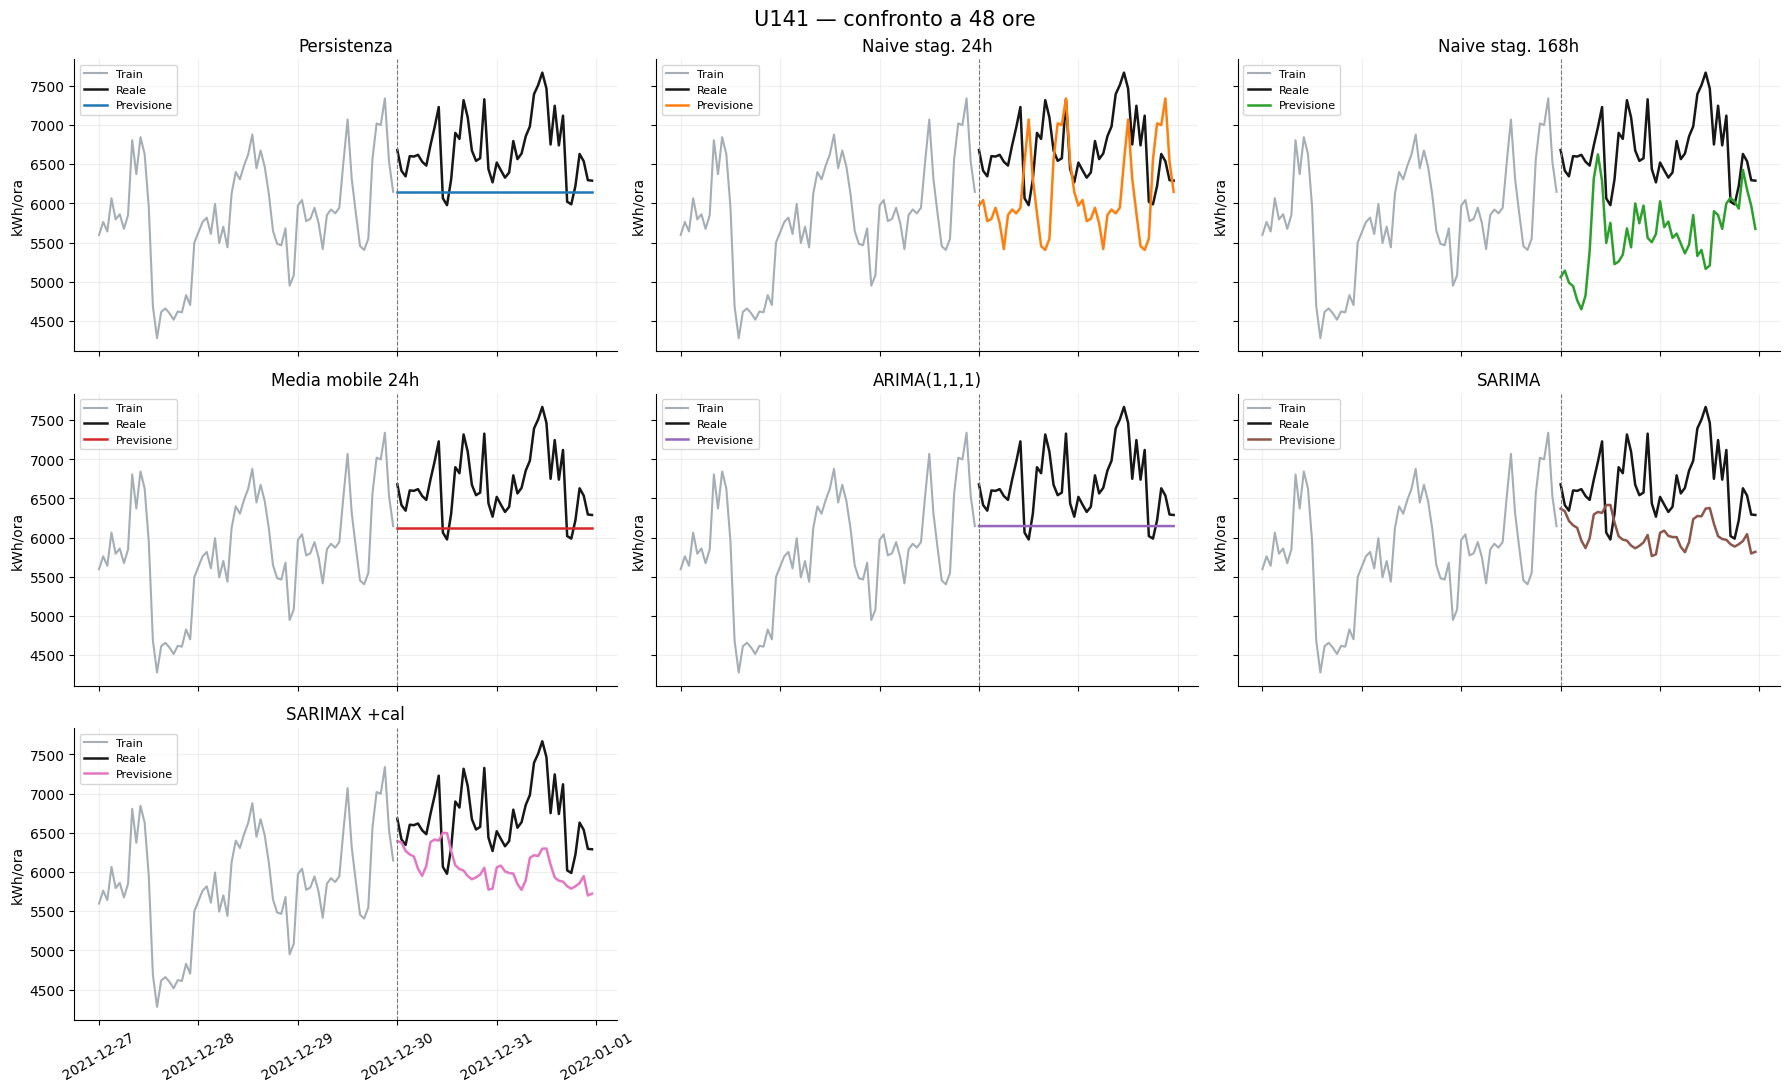

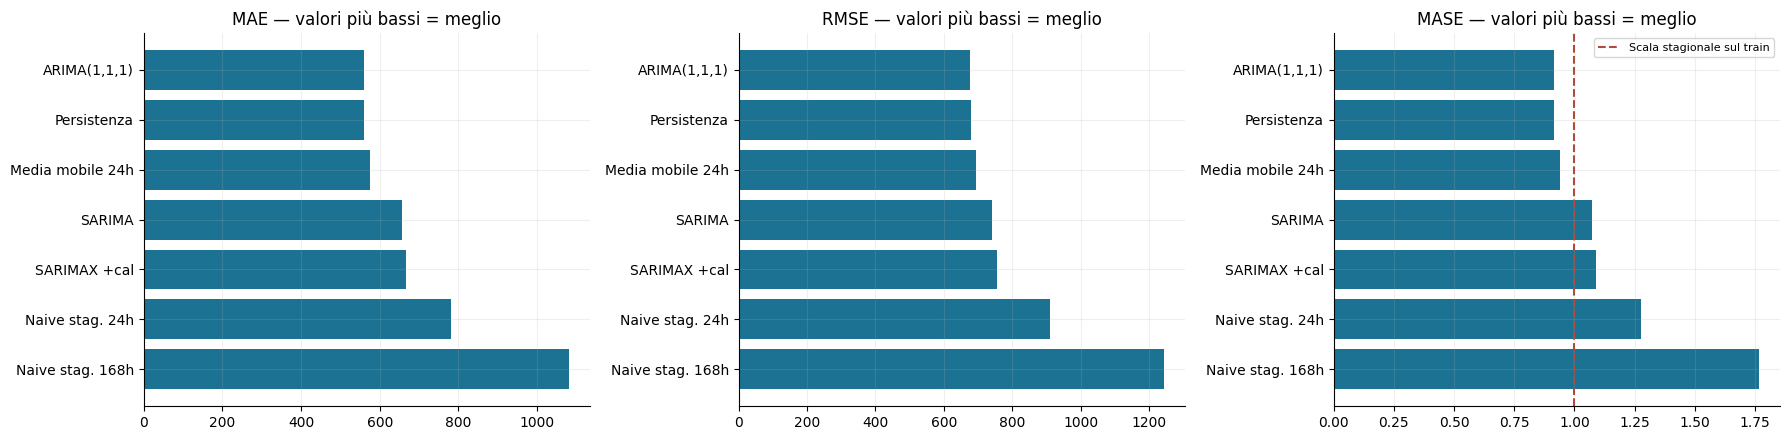

,Reale,Persistenza,Naive stag. 24h,Naive stag. 168h,Media mobile 24h,"ARIMA(1,1,1)",SARIMA,SARIMAX +cal
t,,,,,,,,
2021-12-30 00:00:00,6679.7500,6146.9081,5971.1252,5059.2515,6128.139621,6147.579018,6369.180449,6392.305876
2021-12-30 01:00:00,6416.0757,6146.9081,6042.5370,5141.6497,6128.139621,6147.882235,6337.417503,6378.425880
2021-12-30 02:00:00,6344.6638,6146.9081,5773.3694,4987.8396,6128.139621,6148.019272,6214.222691,6268.902500
2021-12-30 03:00:00,6602.8450,6146.9081,5800.8355,4943.8939,6128.139621,6148.081205,6157.912113,6223.428881
2021-12-30 04:00:00,6597.3517,6146.9081,5943.6591,4762.6178,6128.139621,6148.109196,6124.773863,6198.686690
2021-12-30 05:00:00,6619.3246,6146.9081,5745.9034,4647.2603,6128.139621,6148.121846,5962.269262,6041.731079
2021-12-30 06:00:00,6531.4332,6146.9081,5416.3105,4823.0432,6128.139621,6148.127563,5867.279506,5950.520512
2021-12-30 07:00:00,6481.9944,6146.9081,5850.2744,5388.8443,6128.139621,6148.130146,5991.491869,6076.836050
2021-12-30 08:00:00,6740.1754,6146.9081,5921.6863,6317.1977,6128.139621,6148.131314,6295.686830,6382.095572


In [12]:
def pannelli(tr, te, predictions, names, title, unit, context=72, flags=None):
    ncols = min(3, len(names))
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3.7*nrows), sharex=True, sharey=True, squeeze=False)
    for i, (ax, name) in enumerate(zip(axes.flat, names)):
        ax.plot(tr.index[-context:], tr.iloc[-context:], color='#a5adb5', label='Train')
        ax.plot(te.index, te, color='#171717', lw=1.8, label='Reale')
        if name in predictions:
            ax.plot(te.index, predictions[name], color=plt.get_cmap('tab10')(i % 10), lw=1.8, label='Previsione')
        else:
            ax.text(.5, .5, 'Previsione non disponibile', transform=ax.transAxes, ha='center')
        ax.axvline(te.index[0], color='#777777', ls='--', lw=.8)
        if flags is not None:
            ax.fill_between(te.index, 0, 1, where=np.asarray(flags, bool), transform=ax.get_xaxis_transform(), alpha=.1, color='red')
        ax.set_title(name)
        ax.set_ylabel(unit)
        ax.tick_params(axis='x', rotation=30)
        ax.legend(fontsize=8)
    for ax in list(axes.flat)[len(names):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=15)
    fig.tight_layout()
    plt.show()

pannelli(train, test, predizioni, list(tabella.index), f'{USER} — confronto a {H} ore', 'kWh/ora')
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, metric in zip(axes, ['MAE', 'RMSE', 'MASE']):
    values = pd.to_numeric(tabella.loc[ordine, metric])
    ax.barh(values.index, values, color='#1C7293')
    ax.invert_yaxis()
    ax.set_title(metric + ' — valori più bassi = meglio')
    if metric == 'MASE':
        ax.axvline(1, color='#b04a3a', ls='--', label='Scala stagionale sul train')
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
# Valore reale e tutte le previsioni, timestamp per timestamp.
display(pd.concat([test.rename('Reale'), predizioni], axis=1))

## 4. Qualità del fit affiancata
Gli errori in-sample sono a un passo, dopo 168 ore di assestamento; quelli sul test sono multi-step: il divario non dimostra da solo overfitting. AIC/BIC sono riportati come diagnostica del singolo fit: ordini di differenziazione e inizializzazioni diverse ne limitano la comparabilità.

,"ARIMA(1,1,1)",SARIMA,SARIMAX +cal
Convergenza,True,True,True
AIC,21722.851992,20890.590468,20899.857291
BIC,21738.662931,20916.85782,20957.645465
MAE train (1 passo),319.644024,281.880897,281.193613
MAE test (multi-step),559.881061,656.166933,667.555999


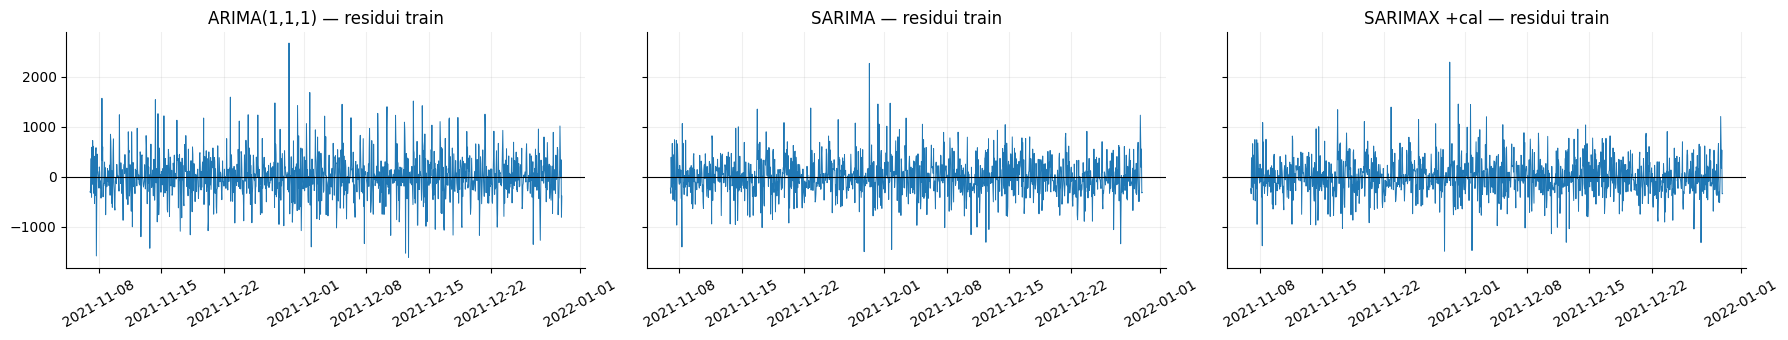

In [13]:
diagnostica = {}
for name, r in fits.items():
    error = train.iloc[168:] - r.fittedvalues.reindex(train.index).iloc[168:]
    diagnostica[name] = {'Convergenza': r.mle_retvals.get('converged', False), 'AIC': r.aic, 'BIC': r.bic,
                         'MAE train (1 passo)': error.abs().mean(), 'MAE test (multi-step)': tabella.loc[name, 'MAE']}
display(pd.DataFrame(diagnostica))
if fits:
    fig, axes = plt.subplots(1, len(fits), figsize=(6*len(fits), 3.5), sharey=True, squeeze=False)
    for ax, (name, r) in zip(axes.flat, fits.items()):
        ax.plot(train.index[168:], r.resid.iloc[168:], lw=.7)
        ax.axhline(0, color='black', lw=.8)
        ax.set_title(name + ' — residui train')
        ax.tick_params(axis='x', rotation=30)
    fig.tight_layout()
    plt.show()

## 5. Caso giornaliero: U143 e Capodanno lunare
Stesso esperimento del sorgente: train dal 1 giugno 2016 al 18 gennaio 2019, test fino al 14 febbraio 2019, SARIMA/SARIMAX con periodo 7 e ordini ottimizzati separatamente sul train, con/senza flag lunare −3/+16 giorni. Entrambe le previsioni sono troncate a zero. Questo caso ha unità, utente e orizzonte diversi: le metriche restano separate dal confronto orario. La finestra evento riprende un’impostazione esplorativa del sorgente, non una validazione indipendente.

I giorni con meno di 96 misure sono considerati incompleti: nel solo train vengono sostituiti causalmente dal valore del giorno precedente, riportandone il numero. Il test non viene imputato; eventuali giorni incompleti fermano il confronto. I giorni iniziali senza un precedente valore valido vengono esclusi dal train.

Train giornaliero: 0 giorni imputati; 1 giorni iniziali incompleti esclusi.
Grid search: {'SARIMA': 64, 'SARIMAX +cal': 64} × 2 fold = 256 fit.
Selezione: RMSE medio minimo; richiesti tutti i fold convergenti.
Fit completati: 10/256
Fit completati: 20/256
Fit completati: 30/256
Fit completati: 40/256
Fit completati: 50/256
Fit completati: 60/256
Fit completati: 70/256
Fit completati: 80/256
Fit completati: 90/256
Fit completati: 100/256
Fit completati: 110/256
Fit completati: 120/256
Fit completati: 130/256
Fit completati: 140/256
Fit completati: 150/256
Fit completati: 160/256
Fit completati: 170/256
Fit completati: 180/256
Fit completati: 190/256
Fit completati: 200/256
Fit completati: 210/256
Fit completati: 220/256
Fit completati: 230/256
Fit completati: 240/256
Fit completati: 250/256
Fit completati: 256/256


,modello,candidato,order,seasonal_order,errore_medio,errore_std,fold_validi,secondi,ammissibile
51,SARIMA,51,"(1, 1, 0)","(0, 1, 1, 7)",5543.211476,1633.199896,2,0.357391,True
54,SARIMA,54,"(1, 1, 0)","(1, 1, 0, 7)",5577.452839,729.527857,2,0.103575,True
19,SARIMA,19,"(0, 1, 0)","(0, 1, 1, 7)",5586.197084,1593.343102,2,0.098187,True
16,SARIMA,16,"(0, 1, 0)","(0, 0, 0, 7)",5638.534027,1961.841535,2,0.009795,True
30,SARIMA,30,"(0, 1, 1)","(1, 1, 0, 7)",5640.548337,989.615148,2,0.360664,True
55,SARIMA,55,"(1, 1, 0)","(1, 1, 1, 7)",5657.112800,1765.305375,2,0.457065,True
23,SARIMA,23,"(0, 1, 0)","(1, 1, 1, 7)",5660.503072,1656.326881,2,0.204738,True
27,SARIMA,27,"(0, 1, 1)","(0, 1, 1, 7)",5696.223117,1820.373150,2,0.383090,True
48,SARIMA,48,"(1, 1, 0)","(0, 0, 0, 7)",5706.687879,2062.111507,2,0.010751,True
20,SARIMA,20,"(0, 1, 0)","(1, 0, 0, 7)",5717.591547,2082.736653,2,0.016301,True


/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid value encountered in matmul
  return _core_matmul(x1, x2)
/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: divide by zero encountered in matmul
  return _core_matmul(x1, x2)
/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: overflow encountered in matmul
  return _core_matmul(x1, x2)
/Users/andrea.quarta/Library/Python/3.9/lib/python/site-packages/numpy/linalg/_linalg.py:3220: RuntimeWarning: invalid valu

,SARIMA,SARIMAX + festa
MAE,82.734104,82.734104
RMSE,314.559383,314.559383
sMAPE %,14.814815,14.814815
MASE,0.019533,0.019533
MAE flag=1,171.832369,171.832369
MAE flag=0,0.0,0.0
convergenza,True,True
order,"(1, 1, 0)","(1, 1, 0)"
seasonal_order,"(0, 1, 1, 7)","(0, 1, 1, 7)"


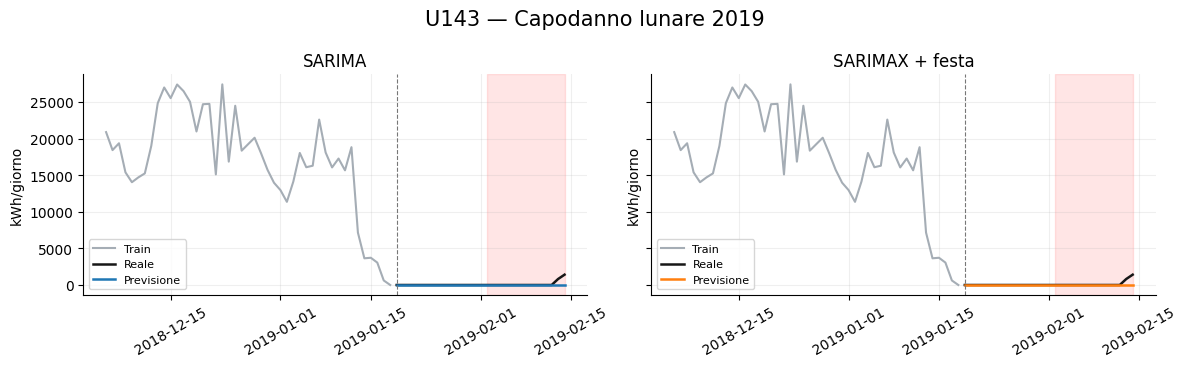

In [14]:
# Serie giornaliera; training su piu Capodanni (2016-2018), previsione del Capodanno 2019
dU = load_user('U143').resample('D').sum(min_count=96).asfreq('D')
seg = dU.loc['2016-06-01':'2019-02-14']
SPLIT = pd.Timestamp('2019-01-18')
tr_d, te_d = seg.loc[:SPLIT], seg.loc[SPLIT + pd.Timedelta(days=1):]

n_missing_train = int(tr_d.isna().sum())
# Imputazione causale solo nel train; le osservazioni del test restano intatte.
tr_d = tr_d.ffill()
n_leading = int(tr_d.isna().sum())
tr_d = tr_d.dropna()
print(f'Train giornaliero: {n_missing_train - n_leading} giorni imputati; {n_leading} giorni iniziali incompleti esclusi.')
assert tr_d.notna().all() and te_d.notna().all(), 'Dati mancanti non imputabili o test incompleto.'

def make_exog_daily(idx, gp=3, gd=16):
    df = pd.DataFrame(index=idx)
    festa = np.zeros(len(idx))
    for d0 in CAPODANNO_LUNARE.values():                       # finestra sul fermo profondo
        a, b = pd.Timestamp(d0)-pd.Timedelta(days=gp), pd.Timestamp(d0)+pd.Timedelta(days=gd)
        festa += ((idx >= a) & (idx <= b)).astype(float)
    df["festa_lunare"] = np.clip(festa, 0, 1)
    return df

EXd = make_exog_daily(seg.index)
exd_tr, exd_te = EXd.loc[tr_d.index], EXd.loc[te_d.index]

# Ricerca separata sul solo train giornaliero, con lo stesso clipping del confronto.
best_daily, classifica_daily, log_daily = ricerca_ordini(
    tr_d, len(te_d), 7, make_exog_daily, clip_zero=True, include_arima=False)
display(classifica_daily.groupby('modello', sort=False).head(10))
verifica_selezione(best_daily, required=('SARIMA', 'SARIMAX +cal'))
# Colonne scelte esclusivamente sul train, poi allineate sul test.
exd_tr, exd_te = make_exog_daily(tr_d.index), make_exog_daily(te_d.index)
cols = exd_tr.columns[exd_tr.std() > 1e-9]
exd_tr, exd_te = exd_tr[cols], exd_te[cols]
order_d, seasonal_d = best_daily['SARIMA']
r_sarima_d = SARIMAX(tr_d, order=order_d, seasonal_order=seasonal_d,
    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=MAXITER)
f_sarima = r_sarima_d.get_forecast(len(te_d)).predicted_mean.clip(lower=0)
order_x, seasonal_x = best_daily['SARIMAX +cal']
r_sarimax_d = SARIMAX(tr_d, exog=exd_tr if len(cols) else None, order=order_x, seasonal_order=seasonal_x,
    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=MAXITER)
f_sarimax = r_sarimax_d.get_forecast(len(te_d), exog=exd_te if len(cols) else None).predicted_mean.clip(lower=0)

pred_daily = pd.DataFrame({'SARIMA': f_sarima, 'SARIMAX + festa': f_sarimax})
flag = exd_te['festa_lunare'].astype(bool)
rows_daily = {}
for name, pred in pred_daily.items():
    row = metriche(tr_d, te_d, pred, m=7)
    error = (te_d - pred).abs()
    row['MAE flag=1'] = error[flag].mean()
    row['MAE flag=0'] = error[~flag].mean()
    r = r_sarima_d if name == 'SARIMA' else r_sarimax_d
    row['convergenza'] = r.mle_retvals.get('converged', False)
    row['order'] = str(r.model.order)
    row['seasonal_order'] = str(r.model.seasonal_order)
    rows_daily[name] = row
display(pd.DataFrame(rows_daily))
pannelli(tr_d, te_d, pred_daily, list(pred_daily), 'U143 — Capodanno lunare 2019', 'kWh/giorno', context=45, flags=flag)

## 6. Walk-forward opzionale: tutti i modelli sugli stessi fold
Impostare `RUN_WALK_FORWARD = True` nella configurazione. Usiamo 12 origini, 30 giorni di train e passo 48h sul segmento operativo più lungo, come nel sorgente, includendo anche naive settimanale e media mobile. Anche ARIMA viene selezionato sul train di ogni fold. L’esecuzione è sequenziale per limitare l’uso di memoria.

Il riepilogo usa solo fold con previsioni valide **per tutti i modelli**; i fallimenti e i fit non convergenti sono conteggiati esplicitamente. Rimane il limite della selezione retrospettiva dei periodi operativi.

La ricerca è **annidata**: viene ripetuta sul train di ogni fold esterno, senza riutilizzare parametri scelti su periodi successivi. Con i default questo aggiunge 272 fit per fold; `tuning_wf` conserva classifiche e log. Se una ricerca non trova candidati ammissibili, l’esecuzione si ferma per consentire la verifica.

In [15]:
if RUN_WALK_FORWARD:
    ok = y >= .05*y[y > 0].median()
    groups = (ok != ok.shift()).cumsum()
    segments = [g for _, g in y.groupby(groups) if ok.loc[g.index].iloc[0]]
    segment = max(segments, key=len)
    n_train = WF_TRAIN_DAYS*24
    assert n_train > max(168, W)
    splits = sorted(sp for sp in (len(segment)-H-i*STEP for i in range(N_FOLDS)) if sp >= n_train)
    if not splits:
        raise ValueError('Nessun fold completo: ridurre train o orizzonte.')
    records = []
    tuning_wf = {}
    for fold, sp in enumerate(splits, 1):
        tr, te = segment.iloc[sp-n_train:sp], segment.iloc[sp:sp+H]
        # Ricerca annidata: ogni fold sceglie i parametri solo sul proprio train.
        best_fold, ranking_fold, log_fold = ricerca_ordini(tr, H, 24, make_exog)
        tuning_wf[fold] = {'classifica': ranking_fold, 'log': log_fold}
        verifica_selezione(best_fold)
        _, scores, _ = confronta(tr, te, best_fold)
        scores = scores.assign(fold=fold, origine=tr.index[-1]).rename_axis('modello').reset_index()
        records.append(scores)
        print(f'Fold {fold}/{len(splits)} completato')
    dettagli_wf = pd.concat(records, ignore_index=True)
    wide = dettagli_wf.pivot(index='fold', columns='modello', values='MASE').apply(pd.to_numeric)
    common = wide.replace([np.inf, -np.inf], np.nan).dropna()
    display(dettagli_wf.groupby('modello').agg(fold_totali=('fold', 'count'),
        non_convergenti=('convergenza', lambda s: sum(v is False or isinstance(v, np.bool_) and not v for v in s)),
        errori=('stato', lambda s: s.str.startswith('ERRORE').sum())))
    print(f'Fold confrontabili per tutti: {len(common)}/{len(splits)}')
    if not common.empty:
        summary = pd.DataFrame({'MASE medio': common.mean(), 'MASE mediano': common.median(), 'MASE std': common.std()})
        display(summary.sort_values('MASE medio').T)
        common.plot.box(vert=False, figsize=(10, 4))
        plt.xlabel('MASE')
        plt.title('Walk-forward — stessi fold per tutti i modelli')
        plt.tight_layout()
        plt.show()
    else:
        print('Nessun confronto aggregato valido: consultare dettagli_wf.')
else:
    print('Walk-forward disattivata. Impostare RUN_WALK_FORWARD = True per eseguirla.')

Walk-forward disattivata. Impostare RUN_WALK_FORWARD = True per eseguirla.


## Lettura dei risultati
- Confrontare errori sullo stesso test e controllare convergenza e warning prima di scegliere un modello.
- I pannelli condividono la scala verticale: eventuali previsioni estreme sono visibili e non nascoste con limiti automatici diversi.
- Verificare se il vantaggio persiste nella walk-forward e su altri utenti. Il caso lunare misura un regime diverso e non entra nella classifica oraria.
- Nessun vincitore viene dichiarato a priori. Il notebook non salva CSV e non sovrascrive gli output degli esperimenti esistenti.